# Thông tin sinh viên

- MSSV: Nguyễn Chí Cường
- Họ và tên: 23520199


#Bài tập 2


#Kết nối/ Mount đến Google Drive


#Khai báo thư viện


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

from itertools import product
from sklearn.cluster import KMeans

# Đọc dữ liệu


In [2]:
# Hàm đọc dữ liệu từ thư mục folder
def load_images_from_folder(folder: str):
    images = []
    labels = []
    class_names = sorted(os.listdir(folder))

    for label, class_name in enumerate(class_names):
        class_folder = os.path.join(folder, class_name)
        if os.path.isdir(class_folder):
            for filename in os.listdir(class_folder):
                img_path = os.path.join(class_folder, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    images.append(img)
                    labels.append(label)

    return images, labels, class_names

In [3]:
# Đọc dữ liệu từ thư mục Dataset
train_folder = "data/HoaVietNam2025/train"
test_folder = "data/HoaVietNam2025/test"

train_images, train_labels, class_names = load_images_from_folder(train_folder)
test_images, test_labels, _ = load_images_from_folder(test_folder)

y_train = np.array(train_labels)
y_test = np.array(test_labels)

In [4]:
print(f"Nhãn các class: {class_names}")
print(f"Tổng số ảnh trong tập train: {len(train_images)}")
print(f"Tổng số ảnh trong tập test: {len(test_images)}")

Nhãn các class: ['Cuc', 'Dao', 'Lan', 'Mai', 'Sen', 'Tho']
Tổng số ảnh trong tập train: 210
Tổng số ảnh trong tập test: 62


# Thực hiện yêu cầu 1: KNeighborsClassifier

Áp dụng Bộ phân lớp KNeighborsClassifier để thực hiện phân loại. Hãy xác định giá trị của các tham số sao cho Độ chính xác cao nhất:

- n_neighbors: 1 - 10
- weights: {‘uniform’, ‘distance’}
- metric_options = ['braycurtis', 'canberra', 'correlation', 'cosine', 'euclidean', 'minkowski']

Sử dụng đặc trưng về màu sắc: Histogram với 3 thành phần màu RGB


In [5]:
# Hàm tính đặc trưng histogram theo 3 thành RGB
def compute_histogram_feature(image, bins=256):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    feature_vector = []

    for i in range(3):
        hist = cv2.calcHist([image], [i], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        feature_vector.extend(hist)

    return np.array(feature_vector)

In [6]:
# Tính đặc trưng cho các ảnh đã đọc được
X_train_RGB = np.array(
    [compute_histogram_feature(img, bins=256) for img in train_images]
)
X_test_RGB = np.array([compute_histogram_feature(img, bins=256) for img in test_images])


print(f"Kích thước tập train: {X_train_RGB.shape}, {y_train.shape}")
print(f"Kích thước tập test: {X_test_RGB.shape}, {y_test.shape}")

Kích thước tập train: (210, 768), (210,)
Kích thước tập test: (62, 768), (62,)


In [7]:
best_acc = 0
best_params = {}

n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = [
    "braycurtis",
    "canberra",
    "correlation",
    "cosine",
    "euclidean",
    "minkowski",
]

for n_neighbor, weight, metric in product(
    n_neighbors_options, weight_options, metric_options
):
    knn = KNeighborsClassifier(n_neighbors=n_neighbor, weights=weight, metric=metric)
    knn.fit(X_train_RGB, y_train)
    y_pred = knn.predict(X_test_RGB)

    acc = accuracy_score(y_test, y_pred)
    print(
        f"Testing: n_neighbors={n_neighbor},weights={weight}, metric={metric}, Accuracy={acc:.4f}"
    )

    if acc > best_acc:
        best_acc = acc
        best_params = {"n_neighbors": n_neighbor, "weights": weight, "metric": metric}

print("\nTham số tối ưu:", best_params)
print(f"Độ chính xác cao nhất: {best_acc:.4f}")

Testing: n_neighbors=1,weights=uniform, metric=braycurtis, Accuracy=0.6290
Testing: n_neighbors=1,weights=uniform, metric=canberra, Accuracy=0.6774
Testing: n_neighbors=1,weights=uniform, metric=correlation, Accuracy=0.6452
Testing: n_neighbors=1,weights=uniform, metric=cosine, Accuracy=0.6452
Testing: n_neighbors=1,weights=uniform, metric=euclidean, Accuracy=0.6452
Testing: n_neighbors=1,weights=uniform, metric=minkowski, Accuracy=0.6452
Testing: n_neighbors=1,weights=distance, metric=braycurtis, Accuracy=0.6290
Testing: n_neighbors=1,weights=distance, metric=canberra, Accuracy=0.6774
Testing: n_neighbors=1,weights=distance, metric=correlation, Accuracy=0.6452
Testing: n_neighbors=1,weights=distance, metric=cosine, Accuracy=0.6452
Testing: n_neighbors=1,weights=distance, metric=euclidean, Accuracy=0.6452
Testing: n_neighbors=1,weights=distance, metric=minkowski, Accuracy=0.6452
Testing: n_neighbors=2,weights=uniform, metric=braycurtis, Accuracy=0.6452
Testing: n_neighbors=2,weights=un

# Yêu cầu 2:

Từ các giá trị tham số tối ưu. Hãy thực nghiệm so sánh độ chính xác khi sử dụng đặc trưng về màu sắc:

- Histogram với 3 thành phần màu HSV tương ứng 8x8x8
- Moment màu
- Màu chủ đạo


## Các hàm rút trích đặc trưng


In [8]:
# Histogram với 3 thành phần màu HSV tương ứng 8x8x8
def compute_histogram_feature_hsv(image, bins=8):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist(
        [image], [0, 1, 2], None, [bins, bins, bins], [0, 180, 0, 256, 0, 256]
    )
    hist = cv2.normalize(hist, hist).flatten()
    return np.array(hist)

In [9]:
# Đặc trưng Moment màu
def compute_moment_feature(image):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Chuyển sang RGB
    mean = np.mean(image, axis=(0, 1))
    std = np.std(image, axis=(0, 1))
    skewness = np.mean(((image - mean) / (std + 1e-6)) ** 3, axis=(0, 1))
    return np.concatenate([mean, std, skewness])

In [10]:
# Đặc trưng Màu chủ đạo
def compute_dominant_color_feature(image, k=3):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    pixels = image.reshape(-1, 3)
    kmeans = KMeans(n_clusters=k, n_init=10)
    kmeans.fit(pixels)
    return kmeans.cluster_centers_.flatten()

## Mô hình với tham số tốt nhất


In [11]:
best_knn = KNeighborsClassifier(
    n_neighbors=best_params["n_neighbors"],
    weights=best_params["weights"],
    metric=best_params["metric"],
)

## Kết quả khi sử dụng đặc trưng Histogram HSV 8x8x8


In [12]:
X_train_hsv8 = np.array([compute_histogram_feature_hsv(img) for img in train_images])
X_test_hsv8 = np.array([compute_histogram_feature_hsv(img) for img in test_images])

In [13]:
best_knn.fit(X_train_hsv8, y_train)
y_pred_hsv8 = best_knn.predict(X_test_hsv8)

acc_hsv8 = accuracy_score(y_test, y_pred_hsv8)
print(f"Độ chính xác với Histogram HSV 8: {acc_hsv8:.4f}")

Độ chính xác với Histogram HSV 8: 0.7419


## Kết quả khi sử dụng đặc trưng Moment màu


In [14]:
X_train_moment = np.array([compute_moment_feature(img) for img in train_images])
X_test_moment = np.array([compute_moment_feature(img) for img in test_images])

In [15]:
best_knn.fit(X_train_moment, y_train)
y_pred_moment = best_knn.predict(X_test_moment)

acc_moment = accuracy_score(y_test, y_pred_moment)
print(f"Độ chính xác với Moment màu: {acc_moment:.4f}")

Độ chính xác với Moment màu: 0.6290


## Kết quả khi sử dụng đặc trưng Màu chủ đạo


In [16]:
X_train_dominant = np.array(
    [compute_dominant_color_feature(img) for img in train_images]
)
X_test_dominant = np.array([compute_dominant_color_feature(img) for img in test_images])

In [17]:
best_knn.fit(X_train_dominant, y_train)
y_pred_dominant = best_knn.predict(X_test_dominant)
acc_dominant = accuracy_score(y_test, y_pred_dominant)
print(f"Độ chính xác với Màu chủ đạo: {acc_dominant:.4f}")

Độ chính xác với Màu chủ đạo: 0.5161


# Yêu cầu 3

Sử dụng các giá trị tham tối ưu như trong yêu cầu 1.

- Giả sử gọi A là trường hợp sử dụng: Histogram với 3 thành phần màu RGB
- Giả sử gọi B là trường hợp sử dụng: Histogram với 3 thành phần màu HSV tương ứng 16x16x16
  Hãy in ra danh sách các ảnh trong tập test mà trong trường hợp:
- A: sai nhưng B: đúng --> minh họa ưu điểm của B
- A: sai và B: sai --> minh họa những mẫu khó
- A: đúng nhưng B: sai --> minh họa ưu điểm của A


In [18]:
best_knn.fit(X_train_RGB, y_train)
y_pred_rgb = best_knn.predict(X_test_RGB)

acc_RGB = accuracy_score(y_test, y_pred_rgb)
print(f"Độ chính xác với Histogram RGB: {acc_RGB:.4f}")

Độ chính xác với Histogram RGB: 0.6935


In [19]:
X_train_hsv16 = np.array(
    [compute_histogram_feature_hsv(img, 16) for img in train_images]
)
X_test_hsv16 = np.array([compute_histogram_feature_hsv(img, 16) for img in test_images])

In [20]:
best_knn.fit(X_train_hsv16, y_train)
y_pred_hsv16 = best_knn.predict(X_test_hsv16)

acc_hsv16 = accuracy_score(y_test, y_pred_hsv16)
print(f"Độ chính xác với Histogram HSV 16x16x16: {acc_hsv16:.4f}")

Độ chính xác với Histogram HSV 16x16x16: 0.7581


In [21]:
correct_rgb = np.where(y_pred_rgb == y_test)[0]
incorrect_rgb = np.where(y_pred_rgb != y_test)[0]

correct_hsv16 = np.where(y_pred_hsv16 == y_test)[0]
incorrect_hsv16 = np.where(y_pred_hsv16 != y_test)[0]

In [22]:
def show_images(indices, title):
    if len(indices) == 0:
        print(f"Không có ảnh nào thỏa điều kiện: {title}")
        return

    plt.figure(figsize=(12, 6))
    for i, idx in enumerate(indices[:10]):
        plt.subplot(2, 5, i + 1)
        plt.imshow(cv2.cvtColor(test_images[idx], cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.title(
            f"RGB: {class_names[y_pred_rgb[idx]]}\nHSV: {class_names[y_pred_hsv16[idx]]}\nThực tế: {class_names[y_test[idx]]}",
            fontsize=10,
        )

    plt.suptitle(title, fontsize=10)
    plt.show()

Yêu cầu 3.1: Phân loại sai theo RGB nhưng đúng ở HSV


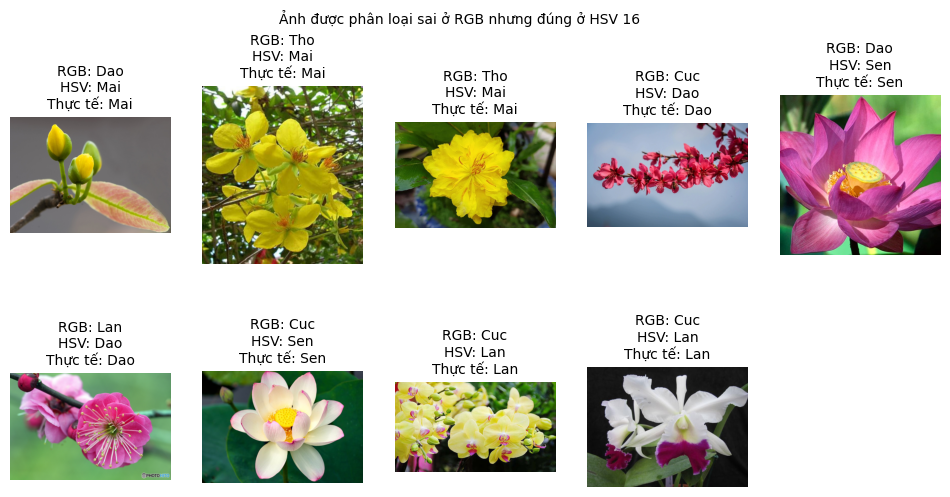

In [23]:
fixed_by_hsv_1 = list(set(incorrect_rgb) & set(correct_hsv16))
show_images(fixed_by_hsv_1, "Ảnh được phân loại sai ở RGB nhưng đúng ở HSV 16")

Yêu cầu 3.2: Phân loại theo RGB đúng nhưng HSV 16 sai


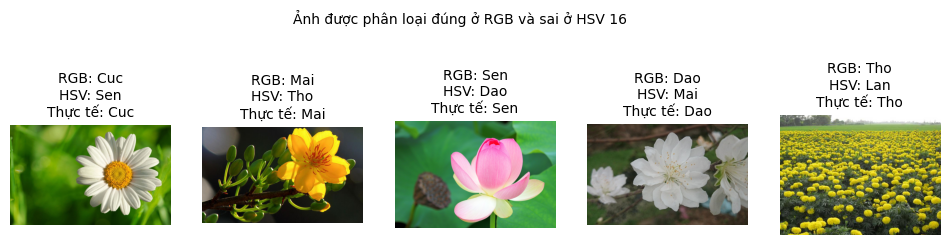

In [24]:
fixed_by_hsv_2 = list(set(correct_rgb) & set(incorrect_hsv16))
show_images(fixed_by_hsv_2, "Ảnh được phân loại đúng ở RGB và sai ở HSV 16")

Yêu cầu 3.3: Phân loại sai theo RGB và HSV 16


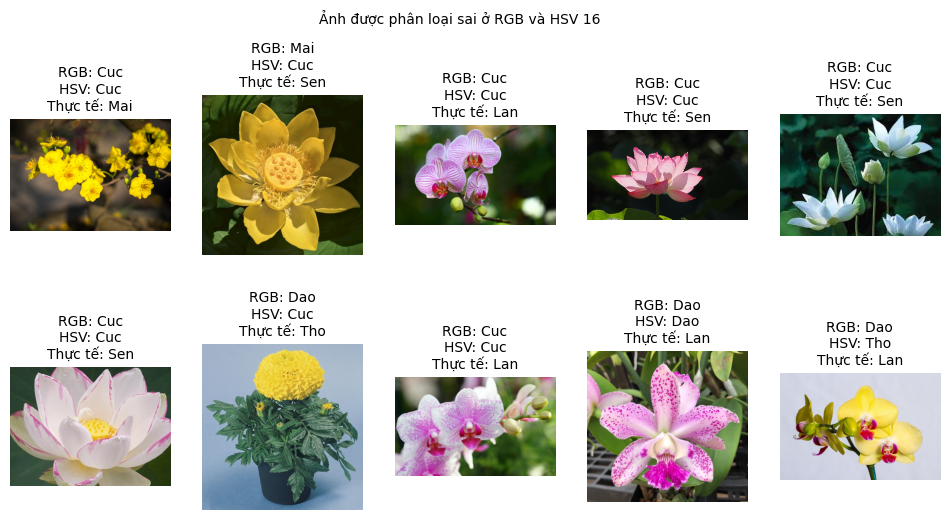

In [25]:
fixed_by_hsv_3 = list(set(incorrect_rgb) & set(incorrect_hsv16))
show_images(fixed_by_hsv_3, "Ảnh được phân loại sai ở RGB và HSV 16")